# Forecasting U.S. Residential Electricity Sales with ARIMA

**ADS 506 Final Project, Team 9**

We are forecasting monthly U.S. residential electricity sales (million kWh) using EIA's *Monthly Energy Review*, Table 7.6. This notebook covers ARIMA. Mason is covering exponential smoothing, and Vince is covering a regression with trend and seasonality, so the team can compare the three approaches.

- **Training set:** Jan 2010 to Jul 2025
- **Test set:** Aug 2025 to Jul 2026 (the last 12 months)

The test year is used only after the model order is fixed. The order is chosen from 12-month forecasts inside the training sample. The test actuals are used later to score that locked model.

1. **Manual model:** ARIMA(0,0,1)(0,1,1)[12] with drift
2. **Automatic model:** whatever `ARIMA()` picks on its own

Packages needed: `install.packages(c("fpp3", "urca"))`. The automatic search uses a KPSS test from `urca` to choose the differences.


In [1]:
suppressPackageStartupMessages(library(fpp3))

# Plot size in the notebook
options(repr.plot.width = 10, repr.plot.height = 5, repr.plot.res = 150)


Warning message:
"package 'fpp3' was built under R version 4.4.3"
Warning message:
"package 'dplyr' was built under R version 4.4.3"
Warning message:
"package 'tidyr' was built under R version 4.4.3"
Warning message:
"package 'lubridate' was built under R version 4.4.3"
Warning message:
"package 'ggplot2' was built under R version 4.4.3"
Warning message:
"package 'tsibble' was built under R version 4.4.3"
Warning message:
"package 'feasts' was built under R version 4.4.3"
Warning message:
"package 'fable' was built under R version 4.4.3"


## 1. Load the data

We use the team's copy of the data in `data/residential_electricity.csv`: residential sales to ultimate customers from the EIA *Monthly Energy Review*, Table 7.6 (series `ESRCPUS`), in million kWh. We keep Jan 2010 through Jul 2026.


In [2]:
sales <- read.csv("data/residential_electricity.csv") |>
  mutate(Month = yearmonth(as.Date(date)), Sales = residential_million_kwh) |>
  select(Month, Sales) |>
  as_tsibble(index = Month) |>
  filter_index("2010 Jan" ~ "2026 Jul")

tail(sales)


Month,Sales
<mth>,<dbl>
2026 Feb,128054.68
2026 Mar,108867.73
2026 Apr,98321.75
2026 May,106659.41
2026 Jun,135594.47
2026 Jul,169665.52


## 2. Train/test split

`train` stops at July 2025. Every model is fit on `train` only. `test` is August 2025 through July 2026, and those actuals are not an input to `model()` or to the order selection below.


In [3]:
train <- sales |> filter_index(~ "2025 Jul")
test  <- sales |> filter_index("2025 Aug" ~ .)

stopifnot(max(train$Month) == yearmonth("2025 Jul"))
stopifnot(min(test$Month) == yearmonth("2025 Aug"))
stopifnot(max(test$Month) == yearmonth("2026 Jul"))
stopifnot(max(train$Month) < min(test$Month))
stopifnot(nrow(test) == 12)
stopifnot(!any(test$Month %in% train$Month))

cat("Train:", format(min(train$Month)), "to", format(max(train$Month)), "(", nrow(train), "months )\n")
cat("Test: ", format(min(test$Month)), "to", format(max(test$Month)), "(", nrow(test), "months )\n")


Train: 2010 Jan to 2025 Jul ( 187 months )
Test:  2025 Aug to 2026 Jul ( 12 months )


## 3. Look at the training data


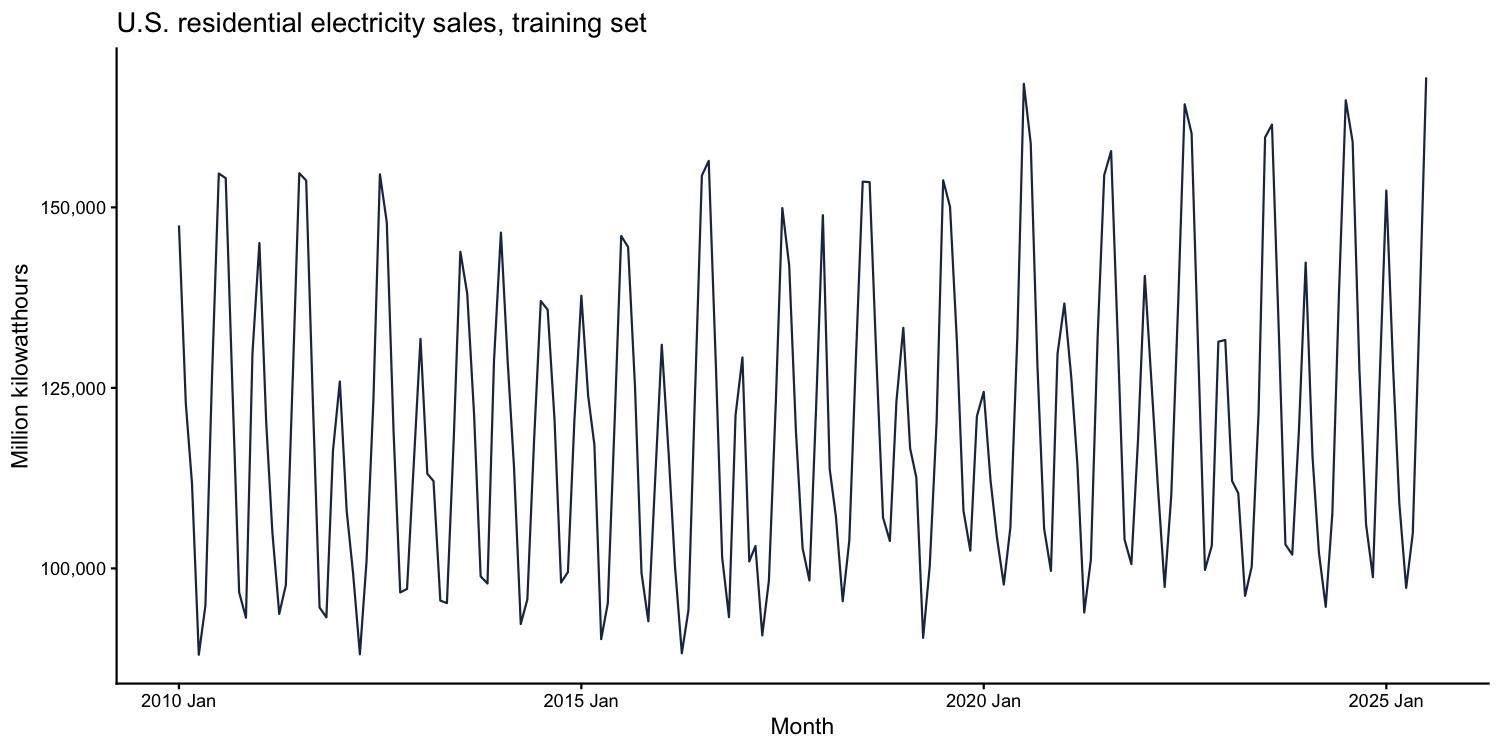

In [4]:
train |>
  autoplot(Sales, colour = "#1F3354") +
  scale_y_continuous(labels = scales::comma) +
  labs(title = "U.S. residential electricity sales, training set",
       x = "Month", y = "Million kilowatthours") +
  theme_classic()


In [5]:
# Average monthly sales for each full year in the training set.
# 2025 is partial (through July), so it is left out of the yearly means.
train |>
  as_tibble() |>
  filter(year(Month) <= 2024) |>
  group_by(Year = year(Month)) |>
  summarise(avg_monthly_sales = round(mean(Sales)), .groups = "drop")


Year,avg_monthly_sales
<dbl>,<dbl>
2010,120476
2011,118567
2012,114543
2013,116234
2014,117267
2015,117008
2016,117588
2017,114887
2018,122424


**Why ARIMA(0,0,1)(0,1,1)[12] with drift?**

- **Seasonal difference and SMA(1):** demand repeats every year, so one seasonal difference keeps a new year close to the year before it. The seasonal moving-average term makes a small correction when that shape shifts.
- **No extra monthly difference:** one seasonal difference is enough. The airline model, which also differences from one month to the next, is only a check.
- **MA(1), not AR(1):** the correlogram points at an AR(1) after the seasonal difference. A rolling 12-month forecast inside the training sample, below, prefers a monthly MA(1). That comparison does not use August 2025 through July 2026.
- **Drift:** in fable this is the constant term once the series has been seasonally differenced. Average monthly sales have risen slowly since 2010. The constant is written as `1` in the formula. A model with no constant is written with `0`.


## 4. Choose the order inside the training sample

The history used for these fits ends 12 months before the end of `train`, so each 12-month forecast still lands on months whose actuals are in `train`. The first window is 10 years. Later windows add one year at a time. The test year is not in this object, and the check below stops the notebook if a validation forecast reaches August 2025.


In [6]:
cv_history <- train |> slice(1:(n() - 12))
cv <- cv_history |> stretch_tsibble(.init = 120, .step = 12)
cv_fit <- cv |>
  model(
    ar1_drift = ARIMA(Sales ~ 1 + pdq(1, 0, 0) + PDQ(0, 1, 1)),
    ar2_drift = ARIMA(Sales ~ 1 + pdq(2, 0, 0) + PDQ(0, 1, 1)),
    ma1_drift = ARIMA(Sales ~ 1 + pdq(0, 0, 1) + PDQ(0, 1, 1)),
    log_ar1 = ARIMA(log(Sales) ~ 1 + pdq(1, 0, 0) + PDQ(0, 1, 1))
  )
cv_fc <- cv_fit |> forecast(h = 12)

stopifnot(max(cv_history$Month) < min(test$Month))
stopifnot(max(cv_fc$Month) < yearmonth("2025 Aug"))
stopifnot(!any(cv_fc$Month %in% test$Month))

cat(
  "Validation forecasts:", format(min(cv_fc$Month)), "to", format(max(cv_fc$Month)),
  "across", dplyr::n_distinct(cv$.id), "windows\n"
)

accuracy(cv_fc, train) |>
  select(.model, RMSE, MAE, MAPE) |>
  arrange(RMSE) |>
  mutate(RMSE = round(RMSE), MAE = round(MAE), MAPE = round(MAPE, 2))


Validation forecasts: 2020 Jan to 2024 Dec across 5 windows


.model,RMSE,MAE,MAPE
<chr>,<dbl>,<dbl>,<dbl>
ma1_drift,6274,5183,4.09
log_ar1,6289,5109,4.04
ar2_drift,6471,5356,4.22
ar1_drift,6529,5395,4.25


The monthly MA(1) with drift has the lowest error on those training forecasts. A log AR(1) is close. The correlogram AR(1) and an AR(2) are worse at the 12-month horizon, even though AR(2) is slightly better on AICc. The manual model is therefore ARIMA(0,0,1)(0,1,1)[12] with drift. That choice is locked before the test year is scored.


## 5. Fit the models on the full training sample

The manual formula is the one selected above. `ARIMA(Sales)` searches and keeps the specification with the lowest AICc. The other names are the correlogram order and nearby checks. Their test errors are reported later. They do not change the manual formula.


In [7]:
fit <- train |>
  model(
    manual = ARIMA(Sales ~ 1 + pdq(0, 0, 1) + PDQ(0, 1, 1)),
    ar1_drift = ARIMA(Sales ~ 1 + pdq(1, 0, 0) + PDQ(0, 1, 1)),
    ar1_sma1 = ARIMA(Sales ~ 0 + pdq(1, 0, 0) + PDQ(0, 1, 1)),
    ma1_sma1 = ARIMA(Sales ~ 0 + pdq(0, 0, 1) + PDQ(0, 1, 1)),
    arma11_sma1 = ARIMA(Sales ~ 0 + pdq(1, 0, 1) + PDQ(0, 1, 1)),
    arma11_sma1_drift = ARIMA(Sales ~ 1 + pdq(1, 0, 1) + PDQ(0, 1, 1)),
    ma2_sma1 = ARIMA(Sales ~ 0 + pdq(0, 0, 2) + PDQ(0, 1, 1)),
    ar2_sma1 = ARIMA(Sales ~ 0 + pdq(2, 0, 0) + PDQ(0, 1, 1)),
    ar2_sma1_drift = ARIMA(Sales ~ 1 + pdq(2, 0, 0) + PDQ(0, 1, 1)),
    ma1_sar1 = ARIMA(Sales ~ 0 + pdq(0, 0, 1) + PDQ(1, 1, 0)),
    airline = ARIMA(Sales ~ 0 + pdq(0, 1, 1) + PDQ(0, 1, 1)),
    auto = ARIMA(Sales, stepwise = TRUE, approximation = FALSE)
  )

# The fitted sample is the training sample, not the test year.
stopifnot(max(fit$manual[[1]]$data$Month) == yearmonth("2025 Jul"))
stopifnot(!any(test$Month %in% fit$manual[[1]]$data$Month))

fit |> select(manual, auto)


manual,auto
<model>,<model>
"<ARIMA(0,0,1)(0,1,1)[12] w/ drift>","<ARIMA(1,0,0)(0,1,1)[12]>"


In [8]:
# Coefficients for the manual model and the automatic model
tidy(fit) |>
  filter(.model %in% c("manual", "auto")) |>
  select(.model, term, estimate, std.error, p.value) |>
  mutate(across(c(estimate, std.error), \(x) round(x, 4)),
         p.value = signif(p.value, 3))


.model,term,estimate,std.error,p.value
<chr>,<chr>,<dbl>,<dbl>,<dbl>
manual,ma1,0.5191,0.0573,2.63e-16
manual,sma1,-0.8882,0.0967,1.18e-16
manual,constant,555.4780,137.2587,7.78e-05
auto,ar1,0.5858,0.0691,9.20e-15
auto,sma1,-0.8174,0.0807,2.86e-19


- **Manual ARIMA(0,0,1)(0,1,1)[12] with drift:** the monthly moving-average coefficient is about 0.52, the seasonal moving-average coefficient is about -0.89, and the drift constant is about 555. The drift is distinguishable from zero. Each year stays close to the year before it, and the level rises slowly.
- **Automatic model:** fable selects ARIMA(1,0,0)(0,1,1)[12] and drops the drift. That is the correlogram order without the constant term.


## 6. Forecast the test set

These forecasts were computed from `train`. The test actuals are drawn and scored here. They are not fed back into the fit.


In [9]:
fc <- fit |> forecast(h = nrow(test))
stopifnot(all(fc$Month %in% test$Month))
stopifnot(!any(fc$Month %in% train$Month))

order_label <- function(mdl) {
  sp <- mdl[[1]]$fit$spec
  lbl <- sprintf("ARIMA(%d,%d,%d)(%d,%d,%d)[12]", sp$p, sp$d, sp$q, sp$P, sp$D, sp$Q)
  if (isTRUE(sp$constant)) paste(lbl, "with drift") else lbl
}

plot_forecast <- function(fc_model, title) {
  acc <- accuracy(fc_model, test)
  intervals <- fc_model |>
    hilo(level = c(80, 95)) |>
    unpack_hilo(c(`80%`, `95%`)) |>
    as_tibble()
  recent <- sales |> filter_index("2022 Jan" ~ .)

  ggplot(mapping = aes(x = Month)) +
    geom_ribbon(data = intervals, aes(ymin = `95%_lower`, ymax = `95%_upper`, fill = "95% interval")) +
    geom_ribbon(data = intervals, aes(ymin = `80%_lower`, ymax = `80%_upper`, fill = "80% interval")) +
    geom_line(data = recent, aes(y = Sales, colour = "Actual")) +
    geom_point(data = test, aes(y = Sales, colour = "Actual"), size = 1) +
    geom_line(data = intervals, aes(y = .mean, colour = "Forecast")) +
    geom_point(data = intervals, aes(y = .mean, colour = "Forecast"), size = 1) +
    geom_vline(xintercept = as.Date(yearmonth("2025 Jul")), linetype = "dashed", colour = "grey40") +
    scale_fill_manual(values = c("95% interval" = "#F5CDB3", "80% interval" = "#E3A277"),
                      breaks = c("95% interval", "80% interval"), name = NULL) +
    scale_colour_manual(values = c(Actual = "#1F3354", Forecast = "#D95F27"), name = NULL) +
    scale_x_yearmonth(breaks = yearmonth(seq(as.Date("2022-01-01"), as.Date("2026-07-01"), by = "6 months")),
                      date_labels = "%Y-%m") +
    scale_y_continuous(labels = scales::comma, breaks = seq(80000, 180000, 20000)) +
    coord_cartesian(ylim = c(75000, 195000)) +
    labs(
      title = title, x = "Month", y = "Million kilowatthours",
      caption = sprintf(
        "U.S. residential electricity sales. Holdout Aug 2025-Jul 2026.  RMSE %s   MAE %s   MAPE %.2f%%",
        scales::comma(acc$RMSE), scales::comma(acc$MAE), acc$MAPE
      )
    ) +
    guides(fill = guide_legend(order = 1), colour = guide_legend(order = 2)) +
    theme_classic(base_size = 13) +
    theme(legend.position = "top", legend.justification = "left",
          plot.caption = element_text(hjust = 0.5, size = 12))
}


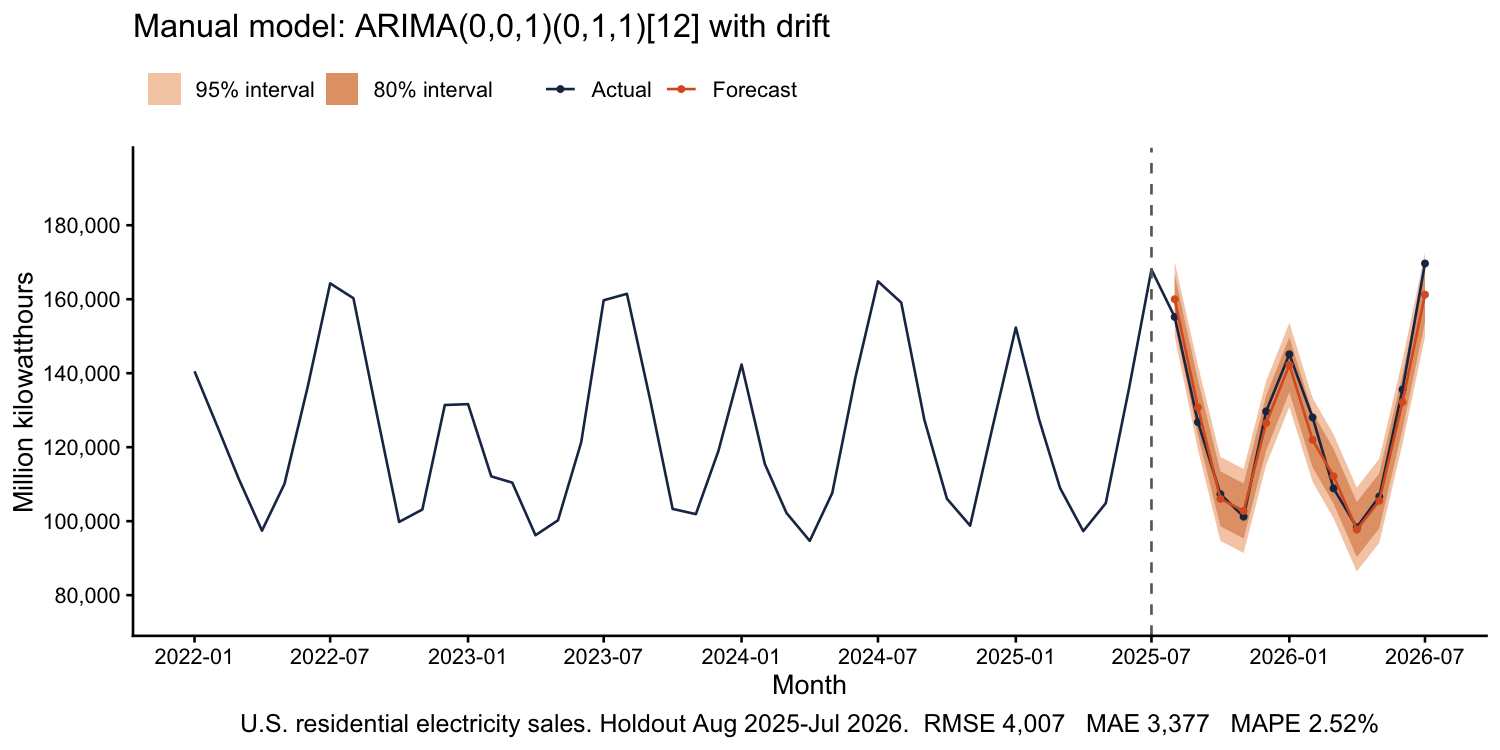

In [10]:
plot_forecast(fc |> filter(.model == "manual"), paste("Manual model:", order_label(fit[["manual"]])))


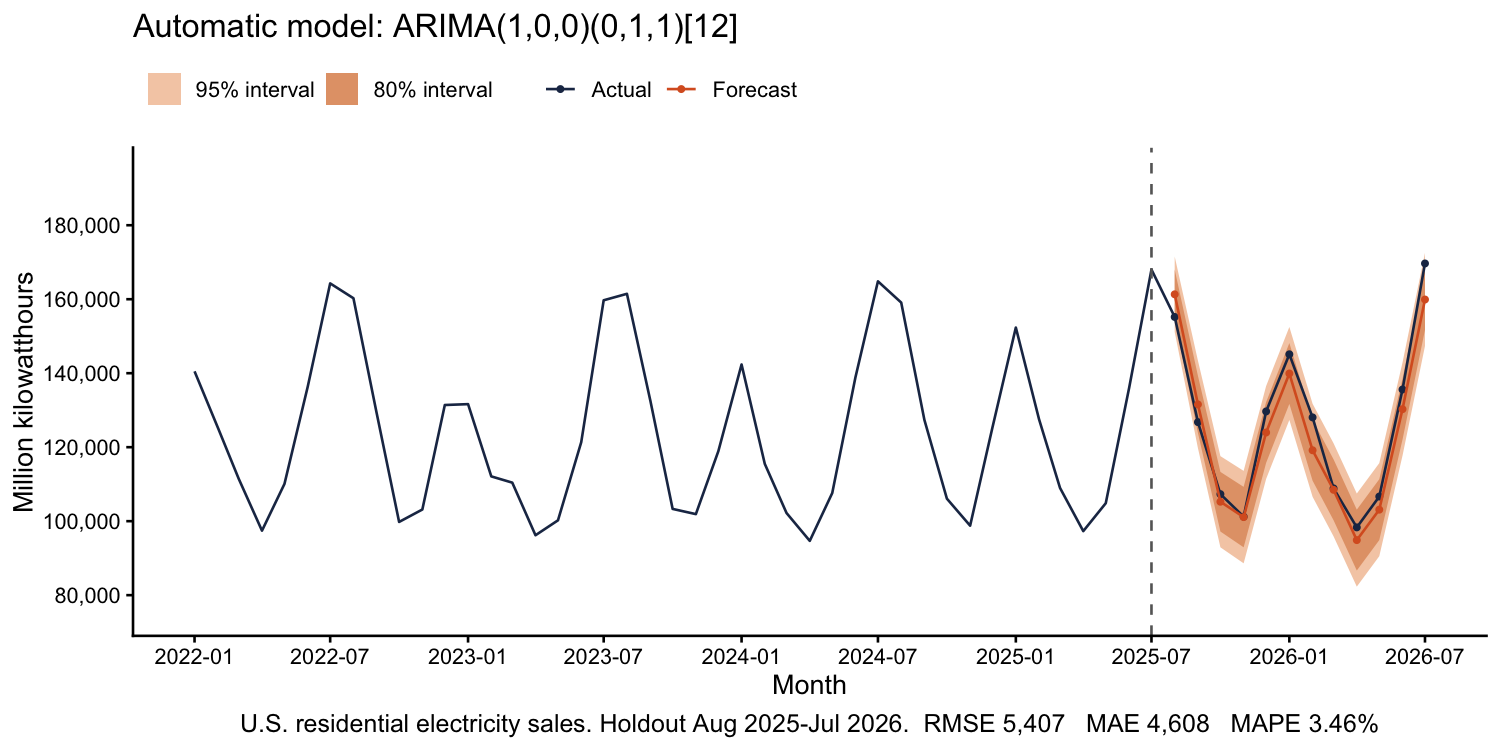

In [11]:
plot_forecast(fc |> filter(.model == "auto"), paste("Automatic model:", order_label(fit[["auto"]])))


## 7. Compare the models

The first table is the locked manual model against the automatic model. The second table is the nearby orders on the same test year. It is a report of the holdout, not a second chance to pick the order.


In [12]:
alias <- c(
  manual = "MA(1) x SMA(1), drift",
  ar1_drift = "AR(1) x SMA(1), drift",
  ar1_sma1 = "AR(1) x SMA(1)",
  ma1_sma1 = "MA(1) x SMA(1)",
  arma11_sma1 = "ARMA(1,1) x SMA(1)",
  arma11_sma1_drift = "ARMA(1,1) x SMA(1), drift",
  ma2_sma1 = "MA(2) x SMA(1)",
  ar2_sma1 = "AR(2) x SMA(1)",
  ar2_sma1_drift = "AR(2) x SMA(1), drift",
  ma1_sar1 = "MA(1) x SAR(1)",
  airline = "Airline (0,1,1)(0,1,1)",
  auto = "Auto"
)

model_names <- vapply(names(alias), \(nm) order_label(fit[[nm]]), character(1))
labels <- tibble(
  .model = names(alias),
  alias = unname(alias),
  model = unname(model_names)
)

lb <- augment(fit) |>
  features(.innov, ljung_box, lag = 24) |>
  select(.model, lb24_p = lb_pvalue)

comparison <- glance(fit) |>
  select(.model, AICc) |>
  left_join(accuracy(fc, test) |> select(.model, RMSE, MAE, MAPE), by = ".model") |>
  left_join(lb, by = ".model") |>
  left_join(labels, by = ".model") |>
  mutate(
    AICc = round(AICc, 1),
    RMSE = round(RMSE),
    MAE = round(MAE),
    MAPE = round(MAPE, 2),
    lb24_p = round(lb24_p, 3)
  ) |>
  select(alias, model, AICc, RMSE, MAE, MAPE, lb24_p)

cat("Manual model and automatic model\n")
comparison |> filter(alias %in% c("MA(1) x SMA(1), drift", "Auto"))

cat("\nNearby orders, sorted by AICc. AICc is from the training fit.\n")
comparison |> arrange(AICc)

cover_one <- function(model_name) {
  iv <- fc |>
    filter(.model == model_name) |>
    hilo(level = c(80, 95)) |>
    unpack_hilo(c(`80%`, `95%`)) |>
    as_tibble() |>
    select(-Sales) |>
    left_join(as_tibble(test) |> select(Month, actual = Sales), by = "Month")
  tibble(
    model = order_label(fit[[model_name]]),
    `months inside 80%` = sum(iv$actual >= iv$`80%_lower` & iv$actual <= iv$`80%_upper`),
    `months inside 95%` = sum(iv$actual >= iv$`95%_lower` & iv$actual <= iv$`95%_upper`)
  )
}

cat("\nHoldout months inside the prediction interval, out of 12\n")
bind_rows(cover_one("manual"), cover_one("auto"))

cat("\nHoldout months. Error is actual minus forecast.\n")
point <- fc |>
  filter(.model %in% c("manual", "auto")) |>
  as_tibble() |>
  select(Month, .model, .mean) |>
  pivot_wider(names_from = .model, values_from = .mean) |>
  left_join(as_tibble(test) |> select(Month, Sales), by = "Month") |>
  mutate(
    manual_error = Sales - manual,
    auto_error = Sales - auto
  )
point |>
  transmute(
    month = format(Month, "%b %Y"),
    actual = round(Sales, 1),
    manual = round(manual, 1),
    auto = round(auto, 1),
    manual_error = round(manual_error, 1),
    auto_error = round(auto_error, 1)
  )


Manual model and automatic model


alias,model,AICc,RMSE,MAE,MAPE,lb24_p
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
"MA(1) x SMA(1), drift","ARIMA(0,0,1)(0,1,1)[12] with drift",3510.3,4007,3377,2.52,0.387
Auto,"ARIMA(1,0,0)(0,1,1)[12]",3509.1,5407,4608,3.46,0.620



Nearby orders, sorted by AICc. AICc is from the training fit.


alias,model,AICc,RMSE,MAE,MAPE,lb24_p
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
"AR(2) x SMA(1), drift","ARIMA(2,0,0)(0,1,1)[12] with drift",3504.0,4506,3738,2.78,0.881
"ARMA(1,1) x SMA(1), drift","ARIMA(1,0,1)(0,1,1)[12] with drift",3504.3,4501,3719,2.77,0.851
"AR(1) x SMA(1), drift","ARIMA(1,0,0)(0,1,1)[12] with drift",3505.2,4566,3757,2.81,0.541
AR(1) x SMA(1),"ARIMA(1,0,0)(0,1,1)[12]",3509.1,5407,4608,3.46,0.620
Auto,"ARIMA(1,0,0)(0,1,1)[12]",3509.1,5407,4608,3.46,0.620
"ARMA(1,1) x SMA(1)","ARIMA(1,0,1)(0,1,1)[12]",3509.5,5368,4652,3.52,0.813
AR(2) x SMA(1),"ARIMA(2,0,0)(0,1,1)[12]",3509.6,5374,4671,3.53,0.807
"MA(1) x SMA(1), drift","ARIMA(0,0,1)(0,1,1)[12] with drift",3510.3,4007,3377,2.52,0.387
MA(2) x SMA(1),"ARIMA(0,0,2)(0,1,1)[12]",3511.9,5019,4382,3.33,0.725



Holdout months inside the prediction interval, out of 12


model,months inside 80%,months inside 95%
<chr>,<int>,<int>
"ARIMA(0,0,1)(0,1,1)[12] with drift",11,12
"ARIMA(1,0,0)(0,1,1)[12]",10,12



Holdout months. Error is actual minus forecast.


month,actual,manual,auto,manual_error,auto_error
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Aug 2025,155203.9,159991.7,161323.6,-4787.8,-6119.8
Sep 2025,126777.5,130734.1,131562.1,-3956.6,-4784.6
Oct 2025,107313.2,106016.4,105257.1,1296.7,2056.1
Nov 2025,101222.4,102771.4,101102.4,-1549.0,120.0
Dec 2025,129666.7,126509.2,123973.7,3157.6,5693.0
Jan 2026,145115.0,142248.0,139921.7,2867.0,5193.3
Feb 2026,128054.7,121977.7,119165.9,6077.0,8888.8
Mar 2026,108867.7,112135.5,108473.0,-3267.8,394.7
Apr 2026,98321.8,97729.0,94885.5,592.8,3436.3


**Takeaways**

- **Order:** inside the training sample, MA(1) x SMA(1) with drift had the lowest 12-month forecast RMSE, about 6,274, ahead of a log AR(1) (about 6,289), AR(2) with drift (about 6,471), and the correlogram AR(1) with drift (about 6,529). Those forecasts end in December 2024.
- **Test year:** the locked manual model beats the automatic model (RMSE about 4,007 vs 5,407, MAE about 3,377 vs 4,608, MAPE 2.52% vs 3.46%). The automatic model drops the drift. AICc still slightly prefers AR(2) with drift and ARMA(1,1) with drift, by about one point, and that was not enough to beat MA(1) on the training forecasts.
- **Where the manual forecast misses:** it is about 4,800 million kWh too high in August 2025. In February 2026 demand comes in about 6,100 above the forecast, and in July 2026 about 8,400 above it. Those are heating and cooling months, and neither model uses temperature.
- **Residuals and intervals:** the Ljung-Box p-value at lag 24 is about 0.39 for the manual model, so the training residuals do not show leftover seasonal correlation. On the test year, 11 of the 12 months fall inside the 80% interval and all 12 fall inside the 95% interval. MA(1) x SAR(1) has a lower test error and a Ljung-Box p-value of about 0.004, so it stays out of the manual model.


## References

U.S. Energy Information Administration. (2026). *Monthly Energy Review, Table 7.6: Electricity end use* [Data set]. https://www.eia.gov/totalenergy/data/browser/?tbl=T07.06
